# 🟠 Tarefa 3

* Disciplina: Física com Python 1 (2026.2) — CBPF
* Autor: Luiz Guilherme Ataliba dos Reis
* Obs: Código desenvolvido para fins de avaliação acadêmica. Disponibilizado publicamente sob a Licença MIT para consulta educacional.

> **Entrega:** colocar no GitHub.

# 🔶 Parte 1

### Teoria da simulação

$m(t)$ conta as partículas na urna A. Em cada passo sorteia uma partícula:
- se ela está em A, passa para B;
- se está em B, passa para A. 

### Média Teórica
$$
\langle m(t)\rangle = \frac{N}{2} + \left(m_0 - \frac{N}{2}\right) \left(1 - \frac{2}{N}\right)^t
$$
### Variância Teórica
Com $x = m - N/2$:
$$
    E[x^2] = \frac{N}{4} + \left(x_0^2 - \frac{N}{4}\right)\left(1 - \frac{4}{N}\right)^t
$$
 

In [50]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import binom, norm
from matplotlib.animation import FuncAnimation
from IPython.display import Image, display

sns.set_theme("notebook")
sns.set_style("darkgrid")

SEED = 42

## 🔵 Simulação e Visualização

In [51]:
def ehrenfest(N, m0, t_max, M, seed=SEED):
    """Simula M réplicas do gás de Ehrenfest: N partículas em duas urnas.
    
    Parâmetros
    - N: Total de partículas
    - m0: N partículas inicialmente na urna A
    - t_max: Tempo de simulação
    - M: Número de réplicas

    m[t, k]: É uma matriz que guarda o total de partículas na urna A, para cada
    tempo t e réplica k. Assim:
    - m[t]: Um vetor, o total de partículas na urna A, para cada réplica, no tempo t
    - m[t, k]: Um escalar, o total de partóculas na urna A, no tempo t e réplica k
    
    Retorna a matriz (t_max + 1, M).
    """
    rng = np.random.default_rng(seed)
    m = np.empty((t_max + 1, M), dtype=np.int32)
    m[0] = m0

    for t in range(t_max):
        # m[t] / N é a prob de selecionar alguém de A. Pegamos então um número aleatório
        # e verificamos se selecionamos alguém de A ou B. 
        sorteou_A = rng.random(M) < m[t] / N

        # Adicionamos ou removemos uma partícula de A, dependendo do resultado anterior
        # np.where aplica isso de forma vetorizada as k réplicas
        m[t + 1] = m[t] + np.where(sorteou_A, -1, 1)
        

    return m


def media_teorica(N, m0, t):
    return N / 2 + (m0 - N / 2) * (1 - 2 / N) ** t


def variancia_teorica(N, m0, t):
    x0 = m0 - N / 2

    return N / 4 + (x0**2 - N / 4) * (1 - 4 / N) ** t - x0**2 * (1 - 2 / N) ** (2 * t)


In [52]:
# Gerando a animação
N_anim = 60
passos = 200
colunas = 6

# Mesma regra usada acima, mas guardando qual partícula está em cada urna, para desenhar.
rng = np.random.default_rng(SEED)
estado = [np.zeros(N_anim, dtype=bool)]  # False = urna B, True = urna A
for _ in range(passos):
    atual = estado[-1].copy()
    idx = rng.integers(N_anim)   # Sorteia uma partícula
    atual[idx] = not atual[idx]  # Move a partícula (inverte)
    estado.append(atual)

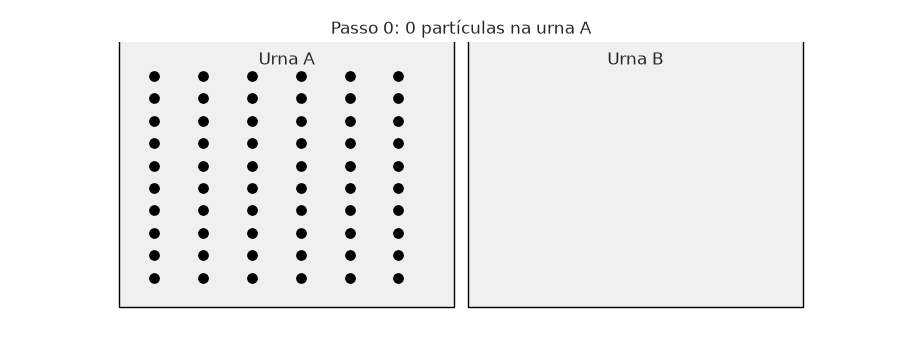

In [53]:
# Plotting
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.set(xlim=(0, 2), ylim=(0, 1.2))
ax.axis("off")

for x, nome in ((0.02, "A"), (1.02, "B")):
    ax.add_patch(plt.Rectangle((x, 0.02), 0.96, 1.2, facecolor="0.94", edgecolor="black"))
    ax.text(x + 0.48, 1.1, f"Urna {nome}", ha="center")

x_slot = (np.arange(N_anim) % colunas) * 0.14
y_slot = (np.arange(N_anim) // colunas) * 0.1
pontos = ax.scatter([], [], s=45, color="black")


def update(frame):
    em_A = estado[frame]
    pontos.set_offsets(np.column_stack([0.12 + x_slot + 0.98 * em_A, 0.15 + y_slot]))
    ax.set_title(f"Passo {frame}: {em_A.sum()} partículas na urna A")


ani = FuncAnimation(fig, update, frames=len(estado) - 1, interval=80)
ani.save("ehrenfest_animation.gif", writer="pillow", fps=12)

plt.close(fig)
display(Image(filename="ehrenfest_animation.gif"))

### 🔷 Interpretação
Todas as partículas começam na urna A, nas primeiras iterações elas se movem para a urna B e depois de um tempo o número de partículas em cada urna se estabiliza. É possível notar pela animação que depois de algumas iterações o número de partículas em A gira em torno de 30, o que seria a divisão perfeita entre as duas urnas.

## 🔵 Média e Variância

In [54]:
# Generating the data
N = 100
m0 = 0
t_max = 400

t = np.arange(t_max + 1)


M = 2000
trajetorias = ehrenfest(N, m0, t_max, M)
media_fast = trajetorias.mean(axis=1)
variancia_fast = trajetorias.var(axis=1)

M = 10000
trajetorias = ehrenfest(N, m0, t_max, M)
media_slow = trajetorias.mean(axis=1)
variancia_slow = trajetorias.var(axis=1)

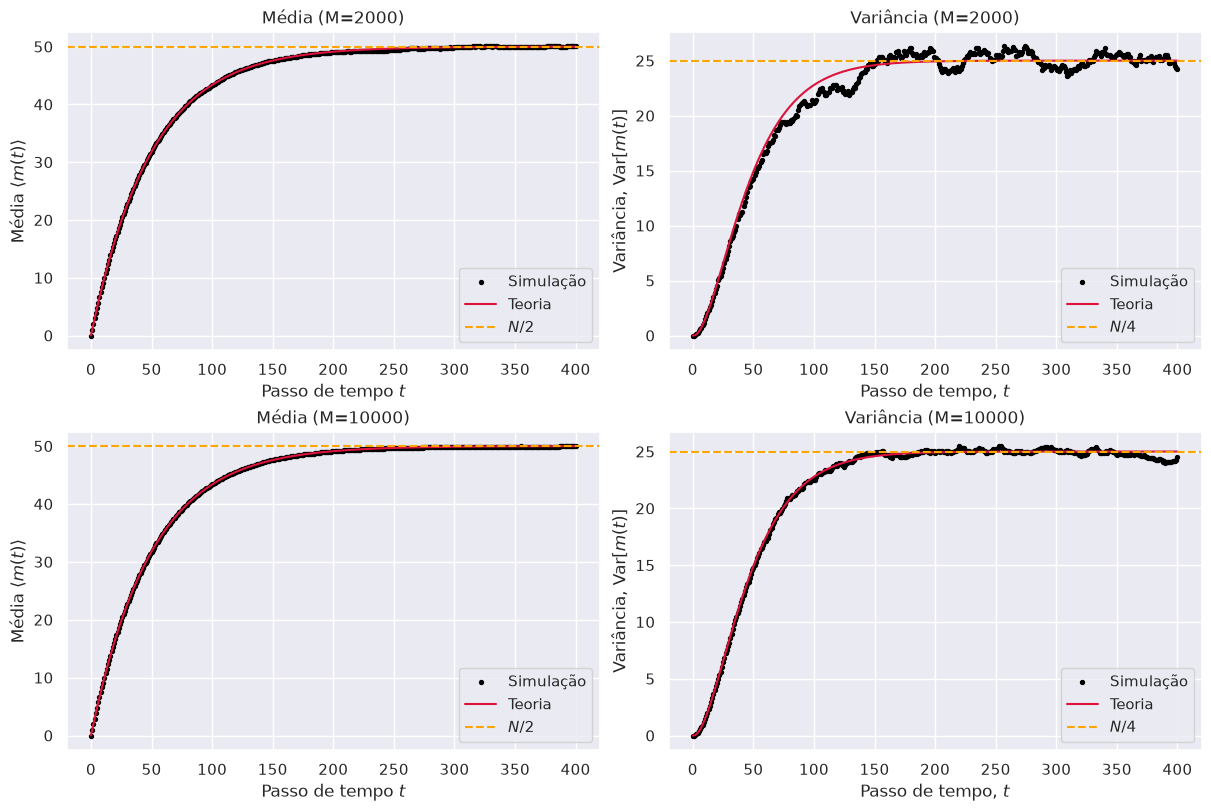

In [55]:
# Plotting

fig, axs = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
axs = axs.flatten()

axs[0].scatter(t, media_fast, s=8, color="black", label="Simulação")
axs[0].plot(t, media_teorica(N, m0, t), color="crimson", label="Teoria")
axs[0].axhline(N / 2, color="orange", ls="--", label="$N/2$")
axs[0].set(
    xlabel="Passo de tempo $t$",
    ylabel="Média $\\langle m(t)\\rangle$",
    title="Média (M=2000)",
)
axs[0].legend()

axs[1].scatter(t, variancia_fast, s=8, color="black", label="Simulação")
axs[1].plot(t, variancia_teorica(N, m0, t), color="crimson", label="Teoria")
axs[1].axhline(N / 4, color="orange", ls="--", label="$N/4$")
axs[1].set(
    xlabel="Passo de tempo, $t$",
    ylabel="Variância, $\\mathrm{Var}[m(t)]$",
    title="Variância (M=2000)",
)
axs[1].legend()


axs[2].scatter(t, media_slow, s=8, color="black", label="Simulação")
axs[2].plot(t, media_teorica(N, m0, t), color="crimson", label="Teoria")
axs[2].axhline(N / 2, color="orange", ls="--", label="$N/2$")
axs[2].set(
    xlabel="Passo de tempo $t$",
    ylabel="Média $\\langle m(t)\\rangle$",
    title="Média (M=10000)",
)
axs[2].legend()

axs[3].scatter(t, variancia_slow, s=8, color="black", label="Simulação")
axs[3].plot(t, variancia_teorica(N, m0, t), color="crimson", label="Teoria")
axs[3].axhline(N / 4, color="orange", ls="--", label="$N/4$")
axs[3].set(
    xlabel="Passo de tempo, $t$",
    ylabel="Variância, $\\mathrm{Var}[m(t)]$",
    title="Variância (M=10000)",
)
axs[3].legend()


### 🔷 Interpretação
É possível notar que os pontos simulados para a média e a variância descrevem o comportamento esperado, de acordo com a curva teórica. Além disso, é possível notar que aumentando o valor de réplicas (M) a simulação se torna cada vez mais próxima da teoria, como prevê a lei dos grandes números, que já foi discutida na atividade anterior.

Além disso, é possível notar que a média e a variância convergem para valores específicos quando $t\to\infty$, respectivamente, $N/2$ e $N/4$. Esse comportamento é discutido na parte teórica, sendo eles:
$$
\lim_{t \to \infty} \langle m(t)\rangle = \frac{N}{2};\\
\lim_{t \to \infty} \text{Var}[m(t)] = \frac{N}{4},
$$


## 🔵 Distribuição

In [56]:
# Generating the data

M_eq = 5000
Ns = [10, 100]

# Para cada N: 5000 réplicas, rodando até t = 20N, para garantir a relaxação do sistema
equilibrio = {}

# Para cada N, vamos gerar as trajétorias, fazer o sampling em tempos específicos e salvar esses resultados
# em uma lista para fazer os gráficos no futuro
for N in Ns:
    trajetorias = ehrenfest(N, 0, 20 * N, M_eq)

    # Selecionando so tempos para o sampling - garantindo o mesmo número de pares e ímpares
    instantes = np.arange(20 * N, 10 * N, -(N + 1))

    equilibrio[N] = np.concatenate([trajetorias[t] for t in instantes])


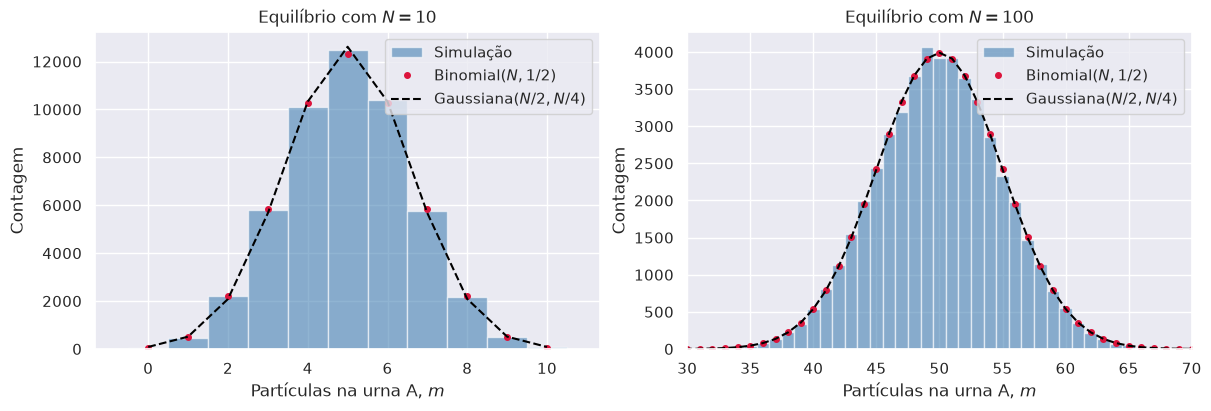

In [57]:
# Plotting

fig, axs = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

for ax, N in zip(axs, Ns):
    amostras = equilibrio[N]
    k = np.arange(N + 1)
    bins = np.arange(-0.5, N + 1.5)

    ax.hist(amostras, bins=bins, color="steelblue", alpha=0.6, label="Simulação")
    ax.plot(
        k,
        len(amostras) * binom.pmf(k, N, 0.5),
        "o",
        color="crimson",
        ms=4,
        label="Binomial$(N, 1/2)$",
    )
    ax.plot(
        k,
        len(amostras) * norm.pdf(k, N / 2, np.sqrt(N / 4)),
        color="black",
        ls="--",
        label="Gaussiana$(N/2, N/4)$",
    )

    ax.set(
        xlabel="Partículas na urna A, $m$",
        ylabel="Contagem",
        xlim=(N / 2 - 4 * np.sqrt(N / 4), N / 2 + 4 * np.sqrt(N / 4)),
    )
    ax.set_title(fr"Equilíbrio com $N = {N}$")
    ax.legend()

### 🔷 Interpretação

Com relação a distribuição desse sistema no equilíbrio, como já esperado pela teoria e também como se é esperado para um sistema dividido em duas caixas como esse, ela segue a regra binomial. Esse fenômeno é observado nas figuras acima, mesmo com $N$ pequeno.

Já para $N$ grande, como espera-se pelo teorema central do limite, uma vez que esse sistema cumpre seus requisitos:
- M é a somo de N variáveis independentes;
- São identicamente distribuídas;
- O sistema possuí média e variância definidas,

essa distribuição tende a uma gaussiana no limite de $N$ grande.

# 🔶 Parte 2

In [58]:
# Implementação

def colisao(w, rng):
    # Sorteia as duas partículas i e j e o número epsilon, uniforme em [0, 1].
    i, j = rng.integers(len(w), size=2)
    epsilon = rng.random()

    # Eq. (3): quantidade de energia transferida
    delta_w = (1 - epsilon) * w[i] - epsilon * w[j]

    # Eqs. (1) e (2): 
    # Se a troca deixaria alguma energia negativa, a colisão é ignorada e w não muda.
    if w[i] - delta_w >= 0 and w[j] + delta_w >= 0:
        w[i] -= delta_w
        w[j] += delta_w


# Simulação
def simular(w, tempos, rng):
    amostras = {0: w.copy()}  # t = 0 já é a primeira amostra

    for t in range(1, tempos[-1] + 1):
        colisao(w, rng)
        if t in tempos:
            amostras[t] = w.copy()

    return amostras

In [59]:
# Inicialização
N = 10**3
E_MAX_0 = 2

rng = np.random.default_rng(SEED)
w = rng.uniform(0, E_MAX_0, N)

print(f"Energia total: {w.sum():.4f}  |  <w>: {w.mean():.4f}")


# Amostragem
TEMPOS = [0, 10, 100, 1_000, 10_000, 100_000]

amostras = simular(w, TEMPOS, rng)

Energia total: 994.3557  |  <w>: 0.9944


Text(0.5, 0.98, 'Convergência para a distribuição de Boltzmann-Gibbs')

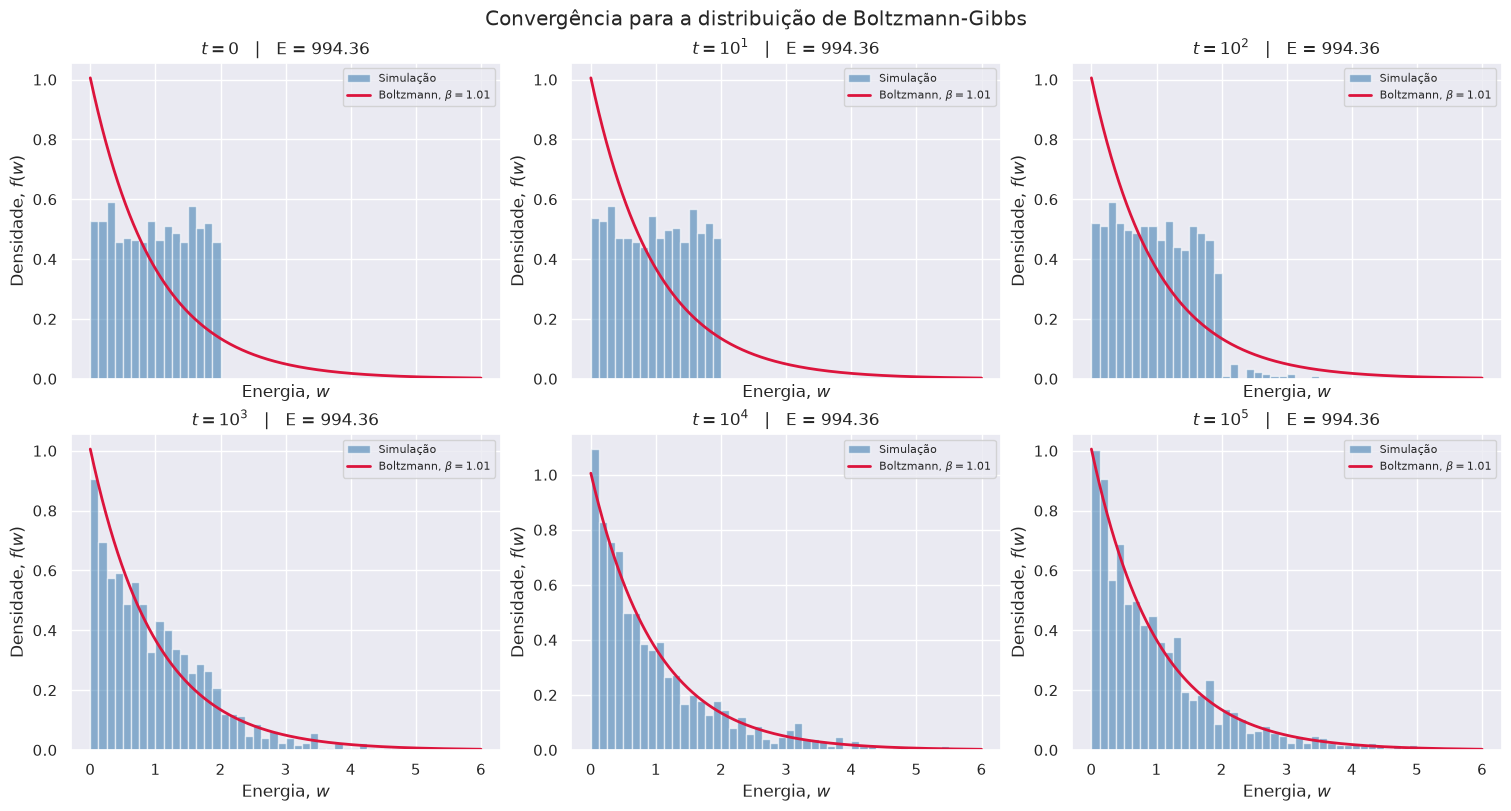

In [60]:
# Análise e visualização

# A energia média final é dada: <w> = 1/beta
beta = 1 / amostras[TEMPOS[-1]].mean()

w_teorico = np.linspace(0, 6, 400)
rotulos = [r"$t = 0$"] + [fr"$t = 10^{{{i}}}$" for i in range(1, 6)]



fig, axs = plt.subplots(2, 3, figsize=(15, 8), sharex=True, constrained_layout=True)

for ax, t, rotulo in zip(axs.flatten(), TEMPOS, rotulos):
    ax.hist(
        amostras[t],
        bins=np.linspace(0, 6, 49),
        density=True,
        color="steelblue",
        alpha=0.6,
        label="Simulação",
    )
    ax.plot(
        w_teorico,
        beta * np.exp(-beta * w_teorico),
        color="crimson",
        lw=2,
        label=fr"Boltzmann, $\beta = {beta:.2f}$",
    )
    ax.set(xlabel="Energia, $w$", ylabel="Densidade, $f(w)$", title=rotulo + f"   |   E = {amostras[t].sum():.2f}")
    ax.legend(fontsize=8)

fig.suptitle("Convergência para a distribuição de Boltzmann-Gibbs")

### 🔷 Interpretação

#### 🔹 1. Evolução do sistema

Inicialmente ((t=0)), temos a distribuição inicial das energias das partículas, que é uniforme no intervalo ([0,2]). À medida que o tempo de simulação avança, mais colisões acontecem, redistribuindo a energia entre as partículas. Dessa forma, observa-se que, com o passar do tempo, a distribuição deixa de ser uniforme e assume um comportamento aproximadamente exponencial, como é evidenciado pela modificação do histograma, que em (t=10^4) e (t=10^5) se aproxima visualmente da curva teórica.


#### 🔹 2. Comparação
Nos instantes iniciais, os histogramas apresentam grande divergência em relação à curva teórica (f(w)=\beta e^{-\beta w}). Conforme o número de colisões aumenta (em tempos de simulação mais longos), os histogramas se aproximam cada vez mais da distribuição teórica, indicando uma convergência para o comportamento esperado. Nos últimos instantes, as distribuições concordam visualmente com a curva teórica. Além disso, a partir de (t=10^4), observamos poucas alterações na distribuição, o que indica uma aproximação do regime estacionário, no qual não há grandes variações na distribuição de energia do sistema.

#### 🔹 3. Energia total
Sim, a energia total do sistema se mantém constante durante toda a evolução, o que é mostrado numericamente pelo valor apresentado acima de cada subplot. Além disso, esse resultado pode ser demonstrado a partir da própria regra de atualização das colisões. Como

$$
    w_i' = w_i - \Delta w;\\
    w_j' = w_j + \Delta w,
$$

temos que:

$$
    E' = w_i' + w_j' = (w_i - \Delta w) + (w_j + \Delta w) = w_i + w_j = E.
$$

Esse resultado é intuitivo e direto de observar, uma vez que exatamente a energia perdida por uma partícula é recebida pela outra. Como as demais partículas não são alteradas, a energia total do sistema também é conservada, não havendo dissipação ou produção de energia.

#### 🔹 4. Condição de energia não negativas
A condição garante que as energias permaneçam dentro dos valores fisicamente permitidos pelo modelo, evitando energias negativas. A presença de partículas com energias negativas também poderia impactar a distribuição de equilíbrio. Por exemplo, se permitíssemos energias negativas sem limite inferior, a distribuição exponencial teórica deixaria de ser normalizável, uma vez que

$$
\int_{-\infty}^\infty \beta e^{-\beta w}dw = \infty,
$$

em contrapartida ao resultado original, em que a integração ocorre no intervalo $[0,\infty)$ e resulta em 1.

# 🔶 Parte 3

Dado um valor de magnetização inicial $m_0$ precisamos descobir o valor correspondente de spins up para iniciar a simulação. Para isso, podemos utilizar as seguintes relações:

A magnetização por spin (inicial) é escrita como:
$$
    m_0 = M_0/N,
$$

e a magnetização total se relaciona com o número de spins por:
$$
    M = N_{up} - N_{down} = N_{up} - (N - N_{up}) = 2N_{up} - N.
$$

Então, o número de spins up é dado por:
$$
    N_{up} = \frac{N + M_0}{2}
$$

Como referência, também vamos utilizar a equação (11) do material, que expressa a magnetização média:
$$
    \langle m_t\rangle = m_0 \left(1-\frac{2}{N}\right)^t
$$

In [ ]:
# Implementação

def simular(N, m0, t_max, replicas, seed=SEED):
    """Cada passo de tempo: 
        1. sorteia-se uma partícula; 
        2. o spin dela troca.
    """
    rng = np.random.default_rng(seed)

    # Estado inicial:
    n_up = round(N * (1 + m0) / 2)
    s = np.full((N, replicas), -1)
    s[:n_up] = 1

    magnetizacao = np.empty((t_max + 1, replicas))
    magnetizacao[0] = s.sum(axis=0)

    colunas = np.arange(replicas)

    for t in range(t_max):
        # 1. uma partícula sorteada por réplica
        i = rng.integers(N, size=replicas)       
        
        # 2. o spin dela troca: M muda em -2 s_i, já que N_up e N_down trocam de lugar
        magnetizacao[t + 1] = magnetizacao[t] - 2 * s[i, colunas]
        s[i, colunas] *= -1

    return magnetizacao


def magnetizacao_media(N, m0, t):
    return m0 * (1 - 2 / N) ** t


def magnetizacao_variancia(N, m0, t):
    return 1 / N + (m0**2 - 1 / N) * (1 - 4 / N) ** t - m0**2 * (1 - 2 / N) ** (2 * t)


### 🔷 Análise da Evolução Temporal (dependência em t)

In [62]:
N = 500
REPLICAS = 2000
t_max = 2000
m0s = [1, 0.5, -0.5, -1]

momentos = {}
for m0 in m0s:
    m = simular(N, m0, t_max, REPLICAS) / N
    momentos[m0] = (m.mean(axis=1), m.var(axis=1))

t = np.arange(t_max + 1)


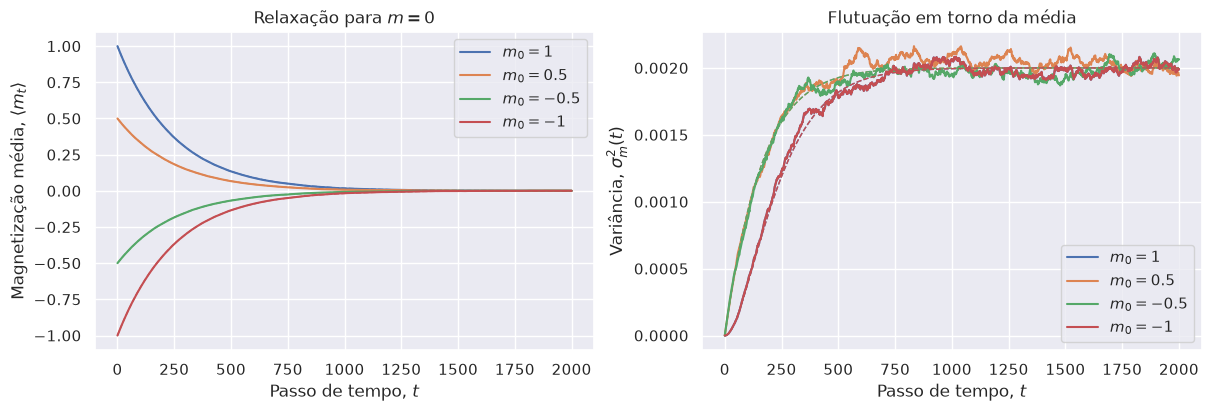

In [68]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

for i, (m0, (media, variancia)) in enumerate(momentos.items()):
    cor = f"C{i}"
    axs[0].plot(t, media, color=cor, label=fr"$m_0 = {m0}$")
    axs[0].plot(t, magnetizacao_media(N, m0, t), color=cor, ls="--", lw=1)
    axs[1].plot(t, variancia, color=cor, label=fr"$m_0 = {m0}$")
    axs[1].plot(t, magnetizacao_variancia(N, m0, t), color=cor, ls="--", lw=1)

for ax in axs:
    ax.set(xlabel="Passo de tempo, $t$")
    ax.legend()

axs[0].set(ylabel="Magnetização média, $\\langle m_t\\rangle$", title="Relaxação para $m = 0$")
axs[1].set(ylabel="Variância, $\\sigma_m^2(t)$", title="Flutuação em torno da média")
plt.show()

### 🔷 Análise da Evolução Temporal (dependência em N)

In [64]:
Ns = [5, 50, 500]
REPLICAS = 2000
t_max = 2000
m0 = 1

por_N = {}
for N in Ns:
    m = simular(N, m0, t_max, REPLICAS) / N
    por_N[N] = (m.mean(axis=1), m.var(axis=1))


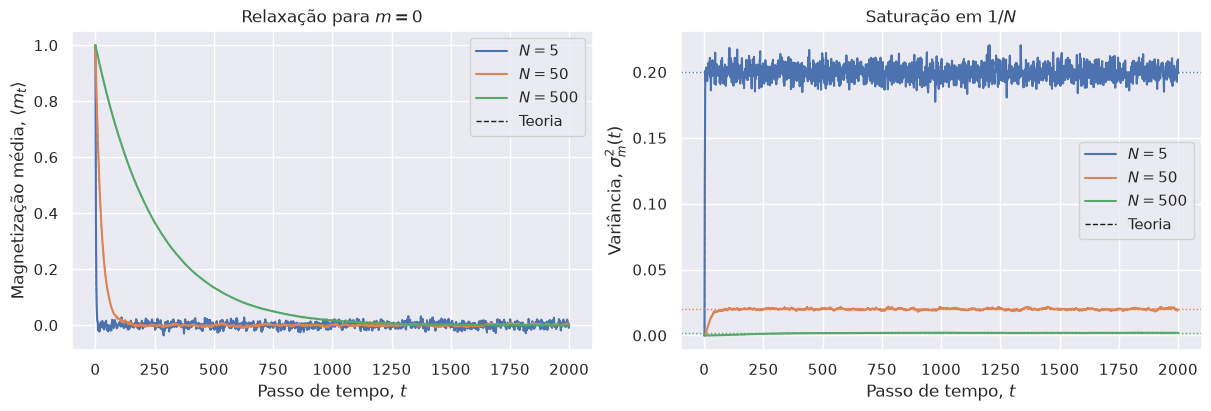

In [65]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

for i, (N, (media, variancia)) in enumerate(por_N.items()):
    cor = f"C{i}"
    axs[0].plot(t, media, color=cor, label=fr"$N = {N}$")
    axs[0].plot(t, magnetizacao_media(N, m0, t), color=cor, ls="--", lw=1)
    axs[1].plot(t, variancia, color=cor, label=fr"$N = {N}$")
    axs[1].plot(t, magnetizacao_variancia(N, m0, t), color=cor, ls="--", lw=1)
    axs[1].axhline(1 / N, color=cor, ls=":", lw=1)

for ax in axs:
    ax.plot([], [], "k--", lw=1, label="Teoria")
    ax.set(xlabel="Passo de tempo, $t$")
    ax.legend()

axs[0].set(ylabel="Magnetização média, $\\langle m_t\\rangle$", title="Relaxação para $m = 0$")
axs[1].set(ylabel="Variância, $\\sigma_m^2(t)$", title="Saturação em $1/N$")
plt.show()

### 🔷 Interpretação - Questões (1-3)

#### 🔹 Q1
Independente da condição inicial da magnetização média $\langle m_t \rangle$ ela sempre converge para zero, o que se é esperado nesse sistema que não possuí a presença de um campo externo. Além disso, as curvas descritas pela evolução temporal são exponenciais, o que está de acordo com o resultado teórico da equação (11). Porém, isso não significa que cada réplica permanece com magnetização exatamente zero, pois as flutuações estatísticas do modelo ainda ocorrem, como é mostrado pela curva da variância em função do tempo, cujo valor no equilíbrio é diferente de zero. 

#### 🔹 Q2
De forma geral, os resultados simulados estão de acordo com a solução analítica, em caráter qualitativo, representando tanto o fenômeno de decaimento exponencial do módulo quanto da convergência para zero da média. 

Entretanto, vale notar que exigem diferenças numéricas entre os valores simulados e teóricos, esse comportamento torna-se mais evidente ao analisar os gráficos de como a magnetização média varia com o número de partículas. Nota-se que o tempo até as medidas de média e variância convergirem varia com o número de partículas, por exemplo, a quanto maior $N$, mais tempo a média leva para convergir. Além disso, é evidente que para ambos os momentos, quanto menor o número de partículas maior é a flutuação no valor simulado, comportamento esse que fica evidenciado no valor do variância, que é maior quanto menor o número de partículas. Resultado esse que está de acordo com o teórico, uma vez que 
$$
    \text{Var}(m) \to \frac{1}{N}
$$

#### 🔹 Q3
Inicialmente, a variância é nula, pois todas as réplicas apresentam a mesma magnetização inicial. Conforme o sistema evolui, as alterações dos spins produzen diferenças entre as réplicas, fazendo com que a variância aumente até atingir o valor estacionário. Teoricamente, a variância de equilíbrio é dada por $\text{Var}(m)=1/N$, resultado confirmado pelos gráficos, como discutido acima.

### 🔷 Análise das flutuações e do estado estacionário

In [66]:
M_eq = 6000
Ns = [5, 50, 500]

# Dois tempos consecutivos: assim m cobre as duas classes de M possíveis, e não só
# metade dos valores que a magnetização pode assumir.
estacionario = {N: simular(N, 1, 4 * N, M_eq)[-2:].ravel() / N for N in Ns}


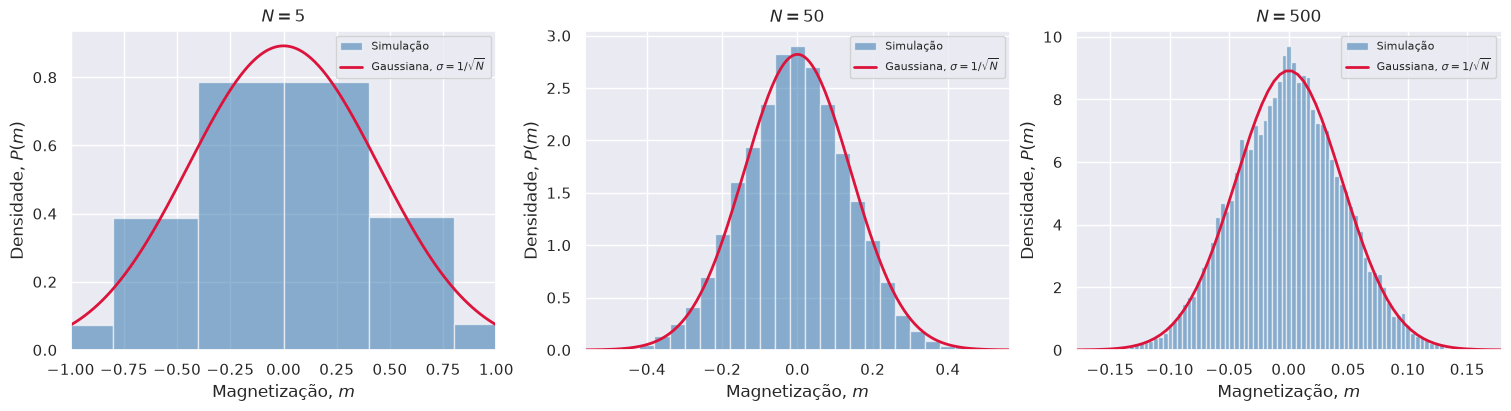

In [67]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

for ax, N in zip(axs, Ns):
    amostras = estacionario[N]
    m_teorico = np.linspace(-1, 1, 400)

    ax.hist(
        amostras,
        bins=np.arange(-1 - 1 / N, 1 + 2 / N, 2 / N),
        density=True,
        color="steelblue",
        alpha=0.6,
        label="Simulação",
    )
    ax.plot(
        m_teorico,
        norm.pdf(m_teorico, 0, np.sqrt(1 / N)),
        color="crimson",
        lw=2,
        label=r"Gaussiana, $\sigma = 1/\sqrt{N}$",
    )

    ax.set(
        xlabel="Magnetização, $m$",
        ylabel="Densidade, $P(m)$",
        title=fr"$N = {N}$",
        xlim=(-min(1, 4 / np.sqrt(N)), min(1, 4 / np.sqrt(N))),
    )
    ax.legend(fontsize=8)

### 🔷 Interpretação (Q4)

#### 🔹Q4
No estado estacionário, a magnetização apresenta uma distribuição binomial (a mesma do gás de Ehrenfest), o que é esperado, pois cada spin tem duas possibilidades (+1 ou -1), com probabilidades iguais. 


Como já discutidos nas partes anteriores dessa atividade, para $N=5$ a natureza discreta da distribuição fica evidente, e ao aumentarmos o valor de $N$, a distribuição da magnetização converge para uma gaussiana. Esse comportamento é descrito pelo Teorema Central do Limite (TCL).

Além disso, pela lei dos grandes números (LGN), podemos concluir que para um grande número de spins independentes, a magnetização média por spin converge para seu valor esperado, que é zero. Dessa forma, LGN explica também porque a gaussiana para qual o sistema converge, é aquela com média zero e variância $1/N$, o sistema converge para gaussiana que expressa seus momentos teóricos.
